# 1. EDA

In [1]:
#202431002_David Lie Agatha
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#202431002_David Lie Agatha
df = pd.read_csv('loan_prediction.csv')
print(df.shape)
print(df)

(614, 13)
      Loan_ID  Gender Married Dependents     Education Self_Employed  \
0    LP001002    Male      No          0      Graduate            No   
1    LP001003    Male     Yes          1      Graduate            No   
2    LP001005    Male     Yes          0      Graduate           Yes   
3    LP001006    Male     Yes          0  Not Graduate            No   
4    LP001008    Male      No          0      Graduate            No   
..        ...     ...     ...        ...           ...           ...   
609  LP002978  Female      No          0      Graduate            No   
610  LP002979    Male     Yes         3+      Graduate            No   
611  LP002983    Male     Yes          1      Graduate            No   
612  LP002984    Male     Yes          2      Graduate            No   
613  LP002990  Female      No          0      Graduate           Yes   

     ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0               5849                0.0         NaN 

In [3]:
#202431002_David Lie Agatha
df.info()
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB
       ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
count       614.000000         614.000000  592.00000

In [4]:
#202431002_David Lie Agatha
print(df.isna().sum())

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


In [5]:
#202431002_David Lie Agatha
kolom_kategorik = df.select_dtypes(include=['object', 'str']).columns
for k in kolom_kategorik:
    print(k, '->', df[k].unique())

Loan_ID -> <StringArray>
['LP001002', 'LP001003', 'LP001005', 'LP001006', 'LP001008', 'LP001011',
 'LP001013', 'LP001014', 'LP001018', 'LP001020',
 ...
 'LP002959', 'LP002960', 'LP002961', 'LP002964', 'LP002974', 'LP002978',
 'LP002979', 'LP002983', 'LP002984', 'LP002990']
Length: 614, dtype: str
Gender -> <StringArray>
['Male', 'Female', nan]
Length: 3, dtype: str
Married -> <StringArray>
['No', 'Yes', nan]
Length: 3, dtype: str
Dependents -> <StringArray>
['0', '1', '2', '3+', nan]
Length: 5, dtype: str
Education -> <StringArray>
['Graduate', 'Not Graduate']
Length: 2, dtype: str
Self_Employed -> <StringArray>
['No', 'Yes', nan]
Length: 3, dtype: str
Property_Area -> <StringArray>
['Urban', 'Rural', 'Semiurban']
Length: 3, dtype: str
Loan_Status -> <StringArray>
['Y', 'N']
Length: 2, dtype: str


In [6]:
#202431002_David Lie Agatha
for k in df.columns:
    if not pd.api.types.is_numeric_dtype(df[k]):
        df[k] = df[k].fillna(df[k].mode()[0])
    else:
        df[k] = df[k].fillna(df[k].mean())
print(df.isna().sum())

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


In [7]:
#202431002_David Lie Agatha
print('Data duplikat:', df.duplicated().sum())
df = df.drop_duplicates()
df.info()

Data duplikat: 0
<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             614 non-null    str    
 2   Married            614 non-null    str    
 3   Dependents         614 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      614 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         614 non-null    float64
 9   Loan_Amount_Term   614 non-null    float64
 10  Credit_History     614 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


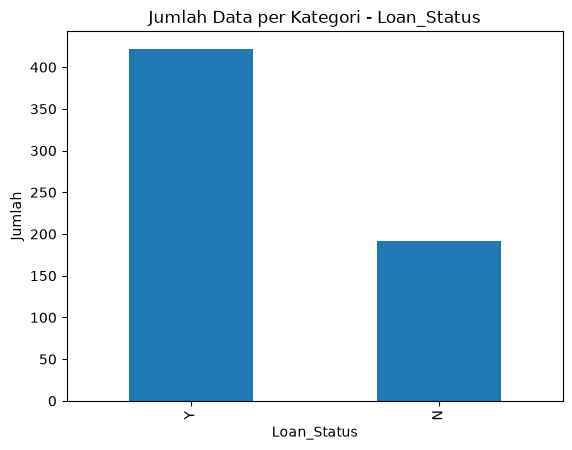

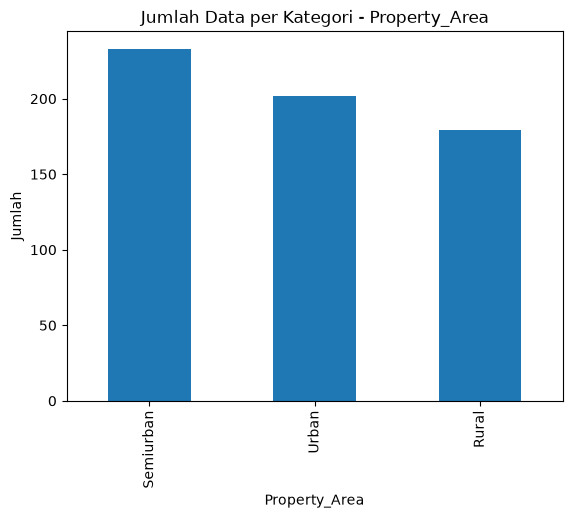

In [8]:
#202431002_David Lie Agatha
for k in ['Loan_Status', 'Property_Area']:
    df[k].value_counts().plot(kind='bar')
    plt.title('Jumlah Data per Kategori - ' + k)
    plt.xlabel(k)
    plt.ylabel('Jumlah')
    plt.show()

# 2. Scraping

In [9]:
#202431002_david Lie agatha
import requests
import csv
from bs4 import BeautifulSoup

200
<!doctype html >
<!--[if IE 8]>    <html class="ie8" lang="en"> <![endif]-->
<!--[if IE 9]>    <html class="ie9" lang="en"> <![endif]-->
<!--[if gt IE 8]><!--> <html dir="ltr" lang="en-US" prefix="og: https://ogp.me/ns#"> <!--<![endif]-->
<head>
<meta charset="UTF-8"/>
<meta name="viewport" content="width=device-width, initial-scale=1.0">
<link rel="pingback" href="https://www.usinflationcalculator.com/xmlrpc.php"/>
<title>U.S. Inflation Rates by Year: Historical Data (1914–2026)</title>
<meta name="description" content="U.S. inflation rates by year show how consumer prices have changed annually based on the Consumer Price Index (CPI) published by the Bureau of Labor Statistics (BLS). The table below provides historical U.S. inflation rate data from 1914 through 2026, allowing readers to compare yearly inflation levels over more than a century. The CPI is"/>
<meta name="robots" content="max-image-preview:large"/>
<link rel="canonical" href="https://www.usinflationcalculator.com/inf
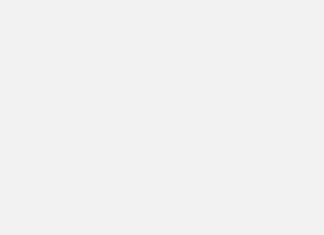
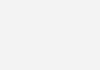
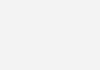
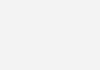
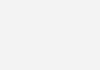
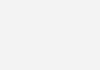
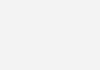

In [10]:
#202431002_david Lie agatha
response = requests.get('https://www.usinflationcalculator.com/inflation/historical-inflation-rates/')
print(response.status_code)
print(response.text)

In [11]:
#202431002_david Lie agatha
soup = BeautifulSoup(response.text, "html.parser")
table = soup.find("table")
rows = table.find_all("tr")
print(f"data tahun yang ditemukan pada website ini sejumlah: {len(rows)-1}") 

data tahun yang ditemukan pada website ini sejumlah: 113


In [12]:
#202431002_david Lie agatha
result = []
for row in rows[1:]:
    cols = row.find_all(["th", "td"])
    if len(cols) >= 13:
        year = cols[0].get_text(strip=True)
        jan = cols[1].get_text(strip=True)
        ave = cols[13].get_text(strip=True)
        result.append({"year": year, "january": jan, "average": ave})

In [13]:
#202431002_david Lie agatha
result = []
table = soup.find("table")
rows = table.find_all("tr")
for row in rows[1:]:
    cols = row.find_all(["th", "td"])
    if len(cols) >= 13:
        year = cols[0].get_text(strip=True)
        january = cols[1].get_text(strip=True)
        average = cols[13].get_text(strip=True)
        
        result.append({"year": year, "january": january, "average": average})

In [14]:
#202431002_david Lie agatha
for item in result:
    print(f"Year: {item['year']} - January: {item['january']} - Average: {item['average']}")

Year: 1914 - January: 2.0 - Average: 1.0
Year: 1915 - January: 1.0 - Average: 1.0
Year: 1916 - January: 3.0 - Average: 7.9
Year: 1917 - January: 12.5 - Average: 17.4
Year: 1918 - January: 19.7 - Average: 18.0
Year: 1919 - January: 17.9 - Average: 14.6
Year: 1920 - January: 17.0 - Average: 15.6
Year: 1921 - January: -1.6 - Average: -10.5
Year: 1922 - January: -11.1 - Average: -6.1
Year: 1923 - January: -0.6 - Average: 1.8
Year: 1924 - January: 3.0 - Average: 0.0
Year: 1925 - January: 0.0 - Average: 2.3
Year: 1926 - January: 3.5 - Average: 1.1
Year: 1927 - January: -2.2 - Average: -1.7
Year: 1928 - January: -1.1 - Average: -1.7
Year: 1929 - January: -1.2 - Average: 0.0
Year: 1930 - January: 0.0 - Average: -2.3
Year: 1931 - January: -7.0 - Average: -9.0
Year: 1932 - January: -10.1 - Average: -9.9
Year: 1933 - January: -9.8 - Average: -5.1
Year: 1934 - January: 2.3 - Average: 3.1
Year: 1935 - January: 3.0 - Average: 2.2
Year: 1936 - January: 1.5 - Average: 1.5
Year: 1937 - January: 2.2 - A

In [44]:
#202431002_david Lie agatha
with open("data_scraping.csv", "w", newline="", encoding="utf-8") as csvfile:
    fieldnames = ["year", "january", "average"]
    writer = csv.DictWriter(csvfile, fieldnames=fieldnames)

    writer.writeheader()
    for item in result:
        writer.writerow(item)

# 3. Regresi Linear

In [18]:
#202431002_David Lie Agatha
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [19]:
#202431002_David Lie Agatha
df = pd.read_csv('data_scraping.csv')
df

,year,january,average
0,1914,2.0,1.0
1,1915,1.0,1.0
2,1916,3.0,7.9
3,1917,12.5,17.4
4,1918,19.7,18.0
...,...,...,...
108,2022,7.5,8.0
109,2023,6.4,4.1
110,2024,3.1,2.9
111,2025,3.0,2.6


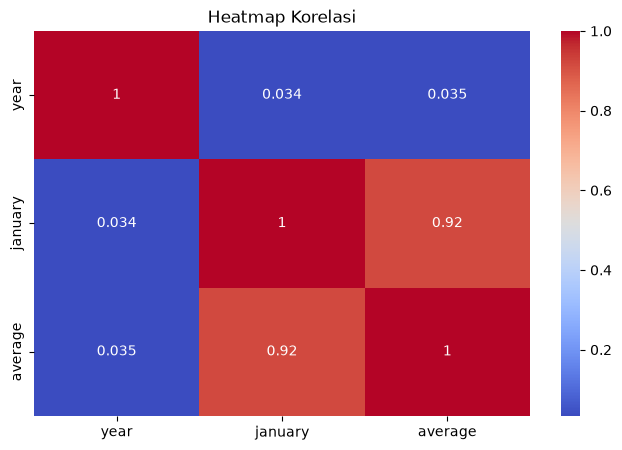

In [20]:
#202431002_David Lie Agatha
plt.figure(figsize=(8,5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Heatmap Korelasi")
plt.show()

In [21]:
#202431002_David Lie Agatha
db_clean = df.dropna(subset=["year", "january", "average"])

x = db_clean[["year", "january"]]
y = db_clean["average"]

In [22]:
#202431002_David Lie Agatha
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

In [23]:
#202431002_David Lie Agatha
lm = LinearRegression()
lm.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[-0.01, 0.86]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['year','january']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,11.12
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [24]:
#202431002_David Lie Agatha
print("Koefisien :", lm.coef_)
print("Intercept :", lm.intercept_)

Koefisien : [-0.00532858  0.86204314]
Intercept : 11.120269803786865


# 4. Decision Tree

In [25]:
#202431002_David Lie Agatha
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn import tree

In [26]:
#202431002_David Lie Agatha
df = pd.read_csv('data_scraping.csv', sep=",")
display(df)
df.info()

,year,january,average
0,1914,2.0,1.0
1,1915,1.0,1.0
2,1916,3.0,7.9
3,1917,12.5,17.4
4,1918,19.7,18.0
...,...,...,...
108,2022,7.5,8.0
109,2023,6.4,4.1
110,2024,3.1,2.9
111,2025,3.0,2.6


<class 'pandas.DataFrame'>
RangeIndex: 113 entries, 0 to 112
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   year     113 non-null    int64  
 1   january  113 non-null    float64
 2   average  112 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 2.8 KB


In [27]:
#202431002_David Lie Agatha
x = df[['average', 'year']] 
display(x)
y = df['january']
display(y)

,average,year
0,1.0,1914
1,1.0,1915
2,7.9,1916
3,17.4,1917
4,18.0,1918
...,...,...
108,8.0,2022
109,4.1,2023
110,2.9,2024
111,2.6,2025


0       2.0
1       1.0
2       3.0
3      12.5
4      19.7
       ... 
108     7.5
109     6.4
110     3.1
111     3.0
112     2.4
Name: january, Length: 113, dtype: float64

In [28]:
#202431002_David Lie Agatha
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=0)

In [29]:
#202431002_David Lie Agatha
model = DecisionTreeRegressor(max_depth=5, random_state=42)
model.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

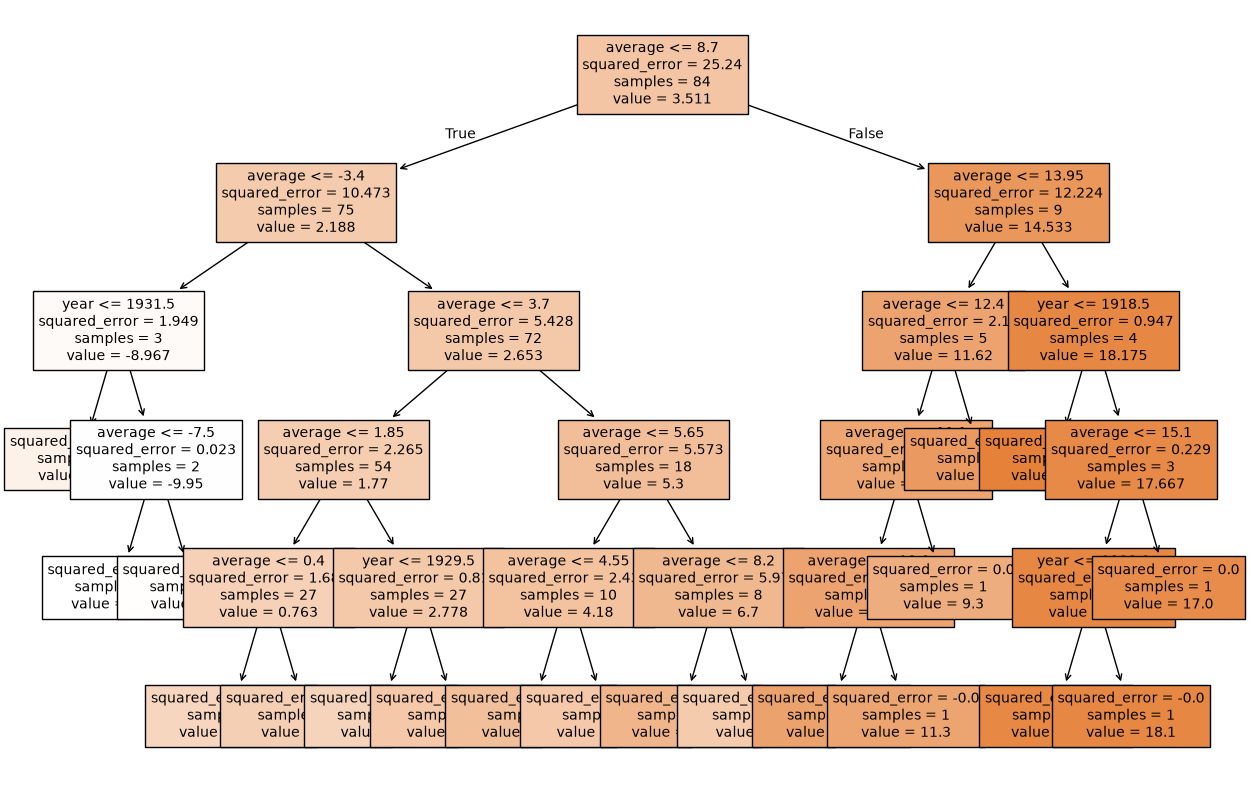

In [30]:
#202431002_David Lie Agatha
plt.subplots(figsize=(15, 10))
tree.plot_tree(model, 
               fontsize=10, 
               feature_names=x.columns, 
               filled=True)
plt.show()

# 5. Naive Bayes

In [32]:
#202431002_David Lie Agatha
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, classification_report

In [33]:
#202431002_David Lie Agatha
df = pd.read_csv('heart.csv')
print(df.head())

   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  


In [34]:
#202431002_David Lie Agatha
df.info()
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB
              Age   RestingBP  Cholesterol   FastingBS       MaxHR  \
count  918.000000  918.000000   918.000000  918.000000  918.000000   
mean    53.510893  132.396514   198.799564    0.233115  136.809368   
std    

In [35]:
#202431002_David Lie Agatha
fitur_numerik = df.drop(columns='HeartDisease').select_dtypes(exclude='object').columns.tolist()
print('Jumlah fitur numerik:', len(fitur_numerik))
print(fitur_numerik)

Jumlah fitur numerik: 6
['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']


In [36]:
#202431002_David Lie Agatha
fitur_kategorikal = df.select_dtypes(include='object').columns.tolist()
print('Jumlah fitur kategorikal:', len(fitur_kategorikal))
print(fitur_kategorikal)

Jumlah fitur kategorikal: 5
['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


C:\Users\David\AppData\Local\Temp\ipykernel_25164\1538618884.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  fitur_kategorikal = df.select_dtypes(include='object').columns.tolist()


In [37]:
#202431002_David Lie Agatha
for k in fitur_kategorikal:
    print(k, '->', df[k].unique())

Sex -> <StringArray>
['M', 'F']
Length: 2, dtype: str
ChestPainType -> <StringArray>
['ATA', 'NAP', 'ASY', 'TA']
Length: 4, dtype: str
RestingECG -> <StringArray>
['Normal', 'ST', 'LVH']
Length: 3, dtype: str
ExerciseAngina -> <StringArray>
['N', 'Y']
Length: 2, dtype: str
ST_Slope -> <StringArray>
['Up', 'Flat', 'Down']
Length: 3, dtype: str


In [38]:
#202431002_David Lie Agatha
le = LabelEncoder()
for k in fitur_kategorikal:
    df[k] = le.fit_transform(df[k])
print(df.head())

   Age  Sex  ChestPainType  RestingBP  Cholesterol  FastingBS  RestingECG  \
0   40    1              1        140          289          0           1   
1   49    0              2        160          180          0           1   
2   37    1              1        130          283          0           2   
3   48    0              0        138          214          0           1   
4   54    1              2        150          195          0           1   

   MaxHR  ExerciseAngina  Oldpeak  ST_Slope  HeartDisease  
0    172               0      0.0         2             0  
1    156               0      1.0         1             1  
2     98               0      0.0         2             0  
3    108               1      1.5         1             1  
4    122               0      0.0         2             0  


In [39]:
#202431002_David Lie Agatha
x = df.drop(columns='HeartDisease')
y = df['HeartDisease']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=0)

In [40]:
#202431002_David Lie Agatha
model = GaussianNB()
model.fit(x_train, y_train)
y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

Evaluasi Training
[[274  44]
 [ 51 319]]
              precision    recall  f1-score   support

           0       0.84      0.86      0.85       318
           1       0.88      0.86      0.87       370

    accuracy                           0.86       688
   macro avg       0.86      0.86      0.86       688
weighted avg       0.86      0.86      0.86       688



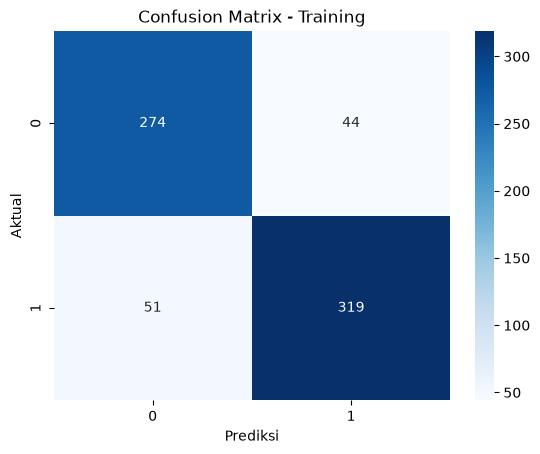

In [41]:
#202431002_David Lie Agatha
print('Evaluasi Training')
print(confusion_matrix(y_train, y_pred_train))
print(classification_report(y_train, y_pred_train))
sns.heatmap(confusion_matrix(y_train, y_pred_train), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Training')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

Evaluasi Testing
[[ 73  19]
 [ 16 122]]
              precision    recall  f1-score   support

           0       0.82      0.79      0.81        92
           1       0.87      0.88      0.87       138

    accuracy                           0.85       230
   macro avg       0.84      0.84      0.84       230
weighted avg       0.85      0.85      0.85       230



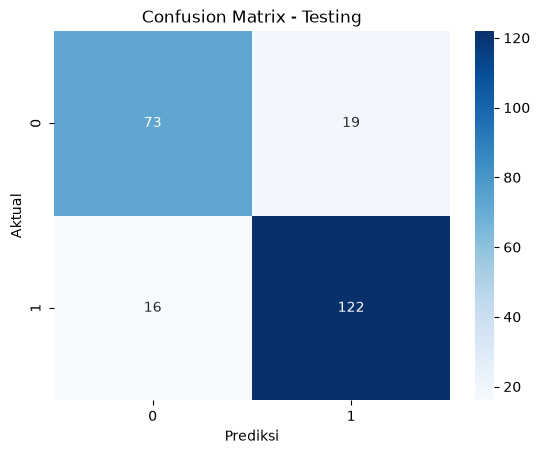

In [42]:
#202431002_David Lie Agatha
print('Evaluasi Testing')
print(confusion_matrix(y_test, y_pred_test))
print(classification_report(y_test, y_pred_test))
sns.heatmap(confusion_matrix(y_test, y_pred_test), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Testing')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

In [43]:
#202431002_David Lie Agatha
data_baru = pd.DataFrame([[54, 1, 0, 130, 240, 0, 1, 140, 1, 1.5, 1]], columns=x.columns)
print('Prediksi:', model.predict(data_baru))

Prediksi: [1]
